# 3.2A — Characteristic profiles of bicycle journeys

**Question:** which journey properties and usage patterns distinguish meaningful groups of bike-sharing trips?
One row is one trip. We retain two complementary representations: **duration–displacement** and **historical trip-link context**, then describe their spatial orientation and cross the results.

Run all cells in order from the project root or `zaka`; five provided CSV files are read directly. All methodological decisions are included here. The annotations are AI-assisted working material to understand and rewrite personally before submission, as required by the assignment.

## 1. Common preparation and decisions

Left joins attach city metadata, bike/type descriptors and both station coordinates; unique reference keys and unchanged trip counts are checked. IDs are join keys, not numerical clustering features. Local time includes daylight-saving changes; weekend and circular hour descriptors are available.

Displacement is the straight-line endpoint distance, not route length. Its ratio to total duration is a descriptive displacement rate, not actual riding speed; it is excluded from active features to avoid counting the same information twice. Raw coordinates, propulsion, form and seats are also outside the retained clustering models; battery variables, nominal range, `rack_locks` and station-status records are unnecessary here.

In [1]:
from pathlib import Path
import os
os.environ.setdefault('LOKY_MAX_CPU_COUNT','2')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import GroupShuffleSplit
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
if not (ROOT / 'data/trips_small.csv').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data'
assert (DATA / 'trips_small.csv').exists(), 'Run from the project root or zaka.'

pd.set_option('display.max_columns', 10)
pd.set_option('display.max_rows', 12)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})

import platform
import sklearn
print(f'Python {platform.python_version()} ; pandas {pd.__version__} ; '
      f'NumPy {np.__version__} ; scikit-learn {sklearn.__version__}')

Python 3.12.0 ; pandas 2.2.3 ; NumPy 2.3.5 ; scikit-learn 1.9.0


In [2]:
trips = pd.read_csv(DATA / 'trips_small.csv', usecols=[
    'bike_id', 'city_id', 'time_start', 'duration', 'distance',
    'lon_start', 'lat_start', 'lon_end', 'lat_end',
    'station_id_start', 'station_id_end'])
cities = pd.read_csv(DATA / 'cities.csv', usecols=[
    'id', 'name', 'lat', 'lon', 'timezone', 'return_to_official_only'])
bikes = pd.read_csv(DATA / 'bikes.csv', usecols=['id', 'bike_type_id'])
types = pd.read_csv(DATA / 'bike_types.csv', usecols=[
    'id', 'propulsion_type', 'form_factor', 'rider_capacity'])
stations = pd.read_csv(DATA / 'stations.csv', usecols=['id', 'lon', 'lat'])

assert not trips.duplicated(['bike_id', 'time_start']).any()
for ref in [cities, bikes, types, stations]:
    assert ref['id'].notna().all() and ref['id'].is_unique


n_trips = len(trips)
table = trips.copy()
table['trip_row'] = np.arange(n_trips)

city_info = cities.rename(columns={
    'id': 'city_id', 'name': 'city_name', 'lat': 'city_lat', 'lon': 'city_lon'})
bike_info = bikes.rename(columns={'id': 'bike_id'})
type_info = types.rename(columns={'id': 'bike_type_id'})
start_info = stations.rename(columns={
    'id': 'station_id_start', 'lon': 'station_start_lon', 'lat': 'station_start_lat'})
end_info = stations.rename(columns={
    'id': 'station_id_end', 'lon': 'station_end_lon', 'lat': 'station_end_lat'})

table = table.merge(city_info, on='city_id', how='left', validate='many_to_one')
table = table.merge(bike_info, on='bike_id', how='left', validate='many_to_one')
table = table.merge(type_info, on='bike_type_id', how='left', validate='many_to_one')
table = table.merge(start_info, on='station_id_start', how='left', validate='many_to_one')
table = table.merge(end_info, on='station_id_end', how='left', validate='many_to_one')
assert len(table) == n_trips and table.trip_row.is_unique

join_log = []
references = [
    ('city_id', cities, 'cities'),
    ('bike_id', bikes, 'bikes'),
    ('bike_type_id', types, 'bike_types'),
    ('station_id_start', stations, 'stations — start'),
    ('station_id_end', stations, 'stations — end'),
]
for key, reference, label in references:
    missing_key = table[key].isna()
    matched = table[key].isin(reference['id'])
    unmatched = ~matched & ~missing_key
    join_log.append({
        'Join': label,
        'trips': len(table),
        'Missing key': int(missing_key.sum()),
        'Unmatched non-missing key': int(unmatched.sum()),
        'Matched (%)': round(100 * matched.mean(), 2),
    })

In [3]:
table['duration_min'] = table['duration'] / 60
table['displacement_km'] = table['distance'] / 1000
valid_motion = table['duration_min'].gt(0) & table['displacement_km'].ge(0)
table['displacement_rate_kmh'] = (
    table['displacement_km'] / (table['duration_min'] / 60)
).where(valid_motion)

utc_start = pd.to_datetime(table['time_start'], unit='s', utc=True, errors='coerce')
table['local_start_hour'] = np.nan
table['local_weekday'] = pd.Series(pd.NA, index=table.index, dtype='Int64')
for timezone, indices in table.groupby('timezone', dropna=True).groups.items():
    local = utc_start.loc[indices].dt.tz_convert(timezone)
    table.loc[indices, 'local_start_hour'] = (
        local.dt.hour + local.dt.minute/60 + local.dt.second/3600)
    table.loc[indices, 'local_weekday'] = local.dt.dayofweek.astype('Int64')
table['weekend'] = table['local_weekday'].ge(5).astype('Int64')

hour_angle = 2 * np.pi * table['local_start_hour'] / 24
table['start_hour_sin'] = np.sin(hour_angle)
table['start_hour_cos'] = np.cos(hour_angle)
assert np.allclose((table['start_hour_sin']**2 + table['start_hour_cos']**2).dropna(), 1)

coordinate_audit = []
position_columns = ['lon_start', 'lat_start', 'lon_end', 'lat_end',
                    'station_start_lon', 'station_start_lat', 'station_end_lon', 'station_end_lat']
for col in position_columns:
    limit = 90 if 'lat' in col else 180
    invalid = table[col].notna() & (~np.isfinite(table[col]) | table[col].abs().gt(limit))
    coordinate_audit.append({'variable':col, 'Outside bounds':int(invalid.sum())})
    table.loc[invalid, col] = np.nan


table['rider_capacity_filled']=table.rider_capacity.fillna(1)
table['multiple_seats']=table.rider_capacity_filled.gt(1).astype('Int64')
trips=table.reset_index(drop=True)
del table
assert trips.trip_row.is_unique
assert trips[['duration_min','displacement_km']].gt(0).all().all()
assert np.isfinite(trips[['duration_min','displacement_km']]).all().all()

cutoffs=trips.groupby('city_id').time_start.quantile([.6,.8]).unstack()
trips['period']=np.select([trips.time_start.le(trips.city_id.map(cutoffs[.6])),
    trips.time_start.le(trips.city_id.map(cutoffs[.8]))],['train','validation'],default='test')
trips['propulsion_context']=trips.propulsion_type.fillna('unknown')
audit_groups={
    'Duration / displacement':(['duration_min','displacement_km'],'Required for physical model'),
    'Local hour / weekend':(['local_start_hour','weekend'],'Required for signatures and description'),
    'Propulsion / form':(['propulsion_type','form_factor'],'Descriptors: missing values retained'),
    'Rider capacity':(['rider_capacity'],'Default one seat; descriptor only'),
    'Start-station coordinates':(['station_start_lat','station_start_lon'],'No imputation; geographical checks'),
    'End-station coordinates':(['station_end_lat','station_end_lon'],'No imputation; geographical checks')}
missing_audit=pd.DataFrame([{'Information':name,'Missing (%)':100*trips[cols].isna().any(axis=1).mean(),
    'Decision':decision}for name,(cols,decision)in audit_groups.items()]).set_index('Information')
display(missing_audit.round(2))
print(f'{len(trips):,} trips ; {trips.city_id.nunique()} systems; '
      f'{100*trips.duration.mod(60).eq(0).mean():.1f}% of durations are multiples of 60 seconds.')

,Missing (%),Decision
Information,,
Duration / displacement,0.00,Required for physical model
Local hour / weekend,0.00,Required for signatures and description
Propulsion / form,0.20,Descriptors: missing values retained
Rider capacity,0.20,Default one seat; descriptor only
Start-station coordinates,9.12,No imputation; geographical checks
End-station coordinates,17.04,No imputation; geographical checks


1,161,376 trips ; 185 systems; 96.9% of durations are multiples of 60 seconds.


**Missing values and extremes.** Required duration, displacement and local-hour fields are complete. The 2,346 trips missing propulsion/form are retained: these are descriptors, and their exclusion would disproportionately remove trips in Komorniki and Luboń. Unknown seats default to one only in a separate descriptor, with originals preserved; missing station coordinates are not invented.

Extremes remain in the main analysis and are tested separately. Observed bounds suggest an undocumented upstream selection; 96.9% of durations are whole minutes, which creates vertical bands in density plots.

**Temporal split within each system:** first 60% for learning, next 20% for comparison, last 20% for description. These periods were explored previously: the checks are internal, not an untouched external test.

## 2. Observe before assigning groups

The grey density shows how duration and displacement vary without cluster labels. Axes are logarithmic; darkness represents log-transformed bin counts. Visible bands may reflect measurement precision rather than distinct populations.

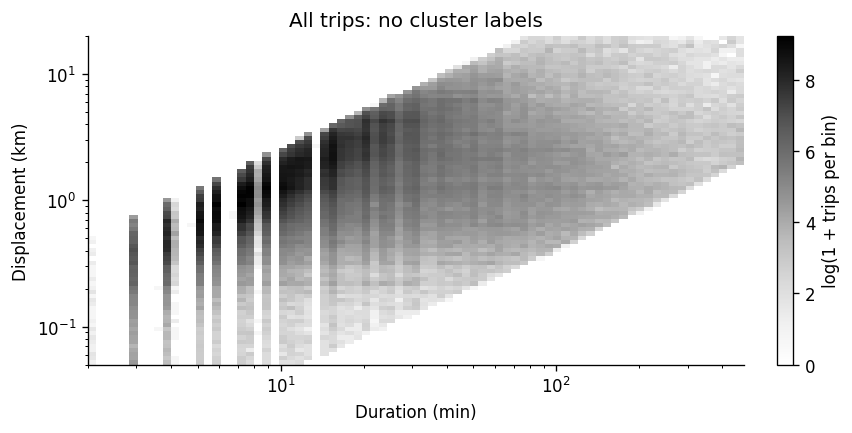

In [4]:
edges = [np.linspace(np.log(2), np.log(480), 80),
         np.linspace(np.log(.05), np.log(20), 80)]
log_values = np.log(trips[['duration_min', 'displacement_km']].to_numpy())
counts = np.histogram2d(log_values[:, 0], log_values[:, 1], bins=edges)[0]
fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
image = ax.pcolormesh(np.exp(edges[0]), np.exp(edges[1]), np.log1p(counts.T), cmap='Greys')
ax.set(xscale='log', yscale='log', xlabel='Duration (min)', ylabel='Displacement (km)', title='All trips: no cluster labels')
fig.colorbar(image, ax=ax, label='log(1 + trips per bin)')
plt.show()

## 3. Physical profiles: duration and displacement

**Hypothesis:** journeys can differ in duration for a comparable endpoint displacement. Log(duration) and log(displacement) are standardized on 80,000 learning trips; the log reduces tail dominance without deleting observations.

A Gaussian mixture allows elongated components and uncertain membership. We compare K=1–8 using approximate ICL = BIC + twice posterior entropy: lower values favour a compact explanation with less overlap. This selects descriptive families, not observed travel purposes.

In [5]:
rng = np.random.default_rng(2026)
period_ids = {}
for period in ['train', 'validation', 'test']:
    period_ids[period] = np.flatnonzero(trips.period == period)
physical_train = rng.choice(period_ids['train'], 80000, replace=False)
physical_valid = rng.choice(period_ids['validation'], 25000, replace=False)
physical_test = rng.choice(period_ids['test'], 30000, replace=False)

log_motion = np.log(trips[['duration_min', 'displacement_km']].to_numpy())
motion_scaler = StandardScaler().fit(log_motion[physical_train])
motion_X = motion_scaler.transform(log_motion)

mixtures = {}
physical_rows = []
with threadpool_limits(limits=2):
    for k in range(1, 9):
        model = GaussianMixture(n_components=k, n_init=4, max_iter=300,
                                reg_covar=1e-4, random_state=42)
        model.fit(motion_X[physical_train])
        assert model.converged_
        probabilities = model.predict_proba(motion_X[physical_train])
        entropy = -(probabilities * np.log(np.maximum(probabilities, 1e-15))).sum()
        validation_probability = model.predict_proba(motion_X[physical_valid]).max(axis=1)
        physical_rows.append({
            'K': k,
            'BIC': model.bic(motion_X[physical_train]),
            'Validation log-likelihood': model.score(motion_X[physical_valid]),
            'converged': model.converged_,
            'ICL_approx': model.bic(motion_X[physical_train]) + 2 * entropy,
            'Membership >= 0.8 (%)': 100 * (validation_probability >= 0.8).mean()})
        mixtures[k] = model

physical_comparison = pd.DataFrame(physical_rows).set_index('K')
physical_k = int(physical_comparison.ICL_approx.idxmin())
motion_model = mixtures[physical_k]
motion_raw = motion_model.predict(motion_X)

median_rates = trips.groupby(motion_raw).displacement_rate_kmh.median()
order = median_rates.sort_values(ascending=False).index
motion_mapping = dict(zip(order, range(1, physical_k + 1)))
trips['physical_profile'] = pd.Series(motion_raw).map(motion_mapping).to_numpy()
trips['motion_probability'] = motion_model.predict_proba(motion_X).max(axis=1)

display(physical_comparison[['ICL_approx', 'Membership >= 0.8 (%)']].rename(columns={'ICL_approx': 'Approximate ICL'}).round(1))
print(f'{physical_k} components selected; '
      f'{100 * trips.motion_probability.lt(.8).mean():.1f}% of trips have maximum membership below 0.8.')

,Approximate ICL,Membership >= 0.8 (%)
K,,
1,422968.9,100.0
2,395812.1,90.1
3,441968.7,52.4
4,462004.3,35.8
5,470161.3,32.1
6,475015.6,32.1
7,485022.1,25.8
8,481809.7,30.0


2 components selected; 9.8% of trips have maximum membership below 0.8.


,Share_pct,Duration_min,Displacement_km,Rate_kmh
physical_profile,,,,
Shorter duration for displacement,77.64,10.0,1.36,8.38
Longer duration for displacement,22.36,33.0,1.27,2.69


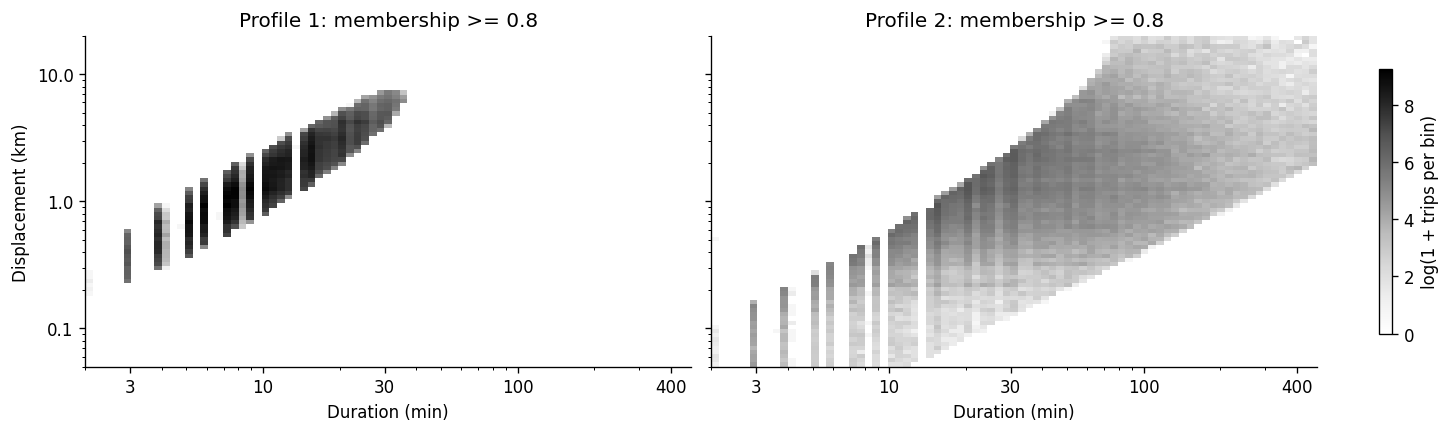

In [6]:
motion_names = {1:'Shorter duration for displacement',2:'Longer duration for displacement'}
physical_profiles = trips.groupby('physical_profile').agg(
    Count=('trip_row','size'), Duration_min=('duration_min','median'),
    Displacement_km=('displacement_km','median'), Rate_kmh=('displacement_rate_kmh','median'),
    Weekend_pct=('weekend',lambda s:100*s.mean()),
    Electric_pct=('propulsion_type',lambda s:100*s.eq('electric_assist').mean()))
physical_profiles.insert(1,'Share_pct',100*physical_profiles.Count/len(trips))
display(physical_profiles[['Share_pct','Duration_min','Displacement_km','Rate_kmh']].rename(index=motion_names).round(2))

edges = [np.linspace(np.log(2),np.log(480),80),np.linspace(np.log(.05),np.log(20),80)]
fig, axes = plt.subplots(1,2,figsize=(12,3.5),sharex=True,sharey=True,layout='constrained')
selections = [np.ones(len(trips),dtype=bool)] + [
    (trips.physical_profile.eq(k)&trips.motion_probability.ge(.8)).to_numpy() for k in [1,2]]
histograms = [np.histogram2d(log_motion[s,0],log_motion[s,1],bins=edges)[0] for s in selections]
vmax = max(np.log1p(h).max() for h in histograms)
for ax,h,title in zip(axes,histograms[1:],['Profile 1: membership >= 0.8','Profile 2: membership >= 0.8']):
    im=ax.pcolormesh(np.exp(edges[0]),np.exp(edges[1]),np.log1p(h.T),cmap='Greys',vmin=0,vmax=vmax,rasterized=True)
    ax.set(xscale='log',yscale='log',xlabel='Duration (min)',title=title)
for ax in axes:
    ax.set_xticks([3,10,30,100,400])
    ax.set_yticks([.1,1,10])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(ScalarFormatter())
axes[0].set_ylabel('Displacement (km)')
fig.colorbar(im,ax=axes,label='log(1 + trips per bin)',shrink=.8)
plt.show()

**Observation:** about 78% of trips have a 10-minute median duration and 1.36-km median displacement; 22% have 33 minutes and 1.27 km. The principal distinction is duration relative to displacement, rather than displacement alone.

**Interpretation and limit:** longer durations could involve detours, stops or other practices; these cannot be distinguished. About 9.8% have maximum membership below 0.8: all trips enter the table, while the group density panels display only memberships ≥0.8 on a common count scale.

## 4. Journey profiles from historical exchange context

**Hypothesis:** the historical exchange rhythms at a journey’s two endpoints describe the context of the link used. We do not cluster stations: each row remains a journey, but trips sharing the same directed station pair share this representation.

For each station, use weekday events from the first 60% of the system history, with arrivals dated at departure plus duration. In eight 3-hour bins, compute **departure share − arrival share**, normalizing departures and arrivals separately. A positive value indicates a relatively departure-oriented time bin, not an absolute surplus of bikes. Add three pseudo-events per bin and require 100 departures **and** 100 arrivals; attach both endpoint signatures to obtain 16 active variables.

In [7]:
known_stations = set(stations.id)
event_parts = []
for side,direction in [('start',1),('end',-1)]:
    valid = trips[f'station_id_{side}'].isin(known_stations)
    e = trips.loc[valid,['city_id',f'station_id_{side}','time_start','duration','timezone']].copy()
    e = e.rename(columns={f'station_id_{side}':'station'})
    e['event_time'] = e.time_start + (e.duration if side=='end' else 0)
    utc = pd.to_datetime(e.event_time,unit='s',utc=True)
    e['hour'],e['weekday'] = np.nan,np.nan
    for tz,indices in e.groupby('timezone').groups.items():
        local = utc.loc[indices].dt.tz_convert(tz)
        e.loc[indices,'hour'] = local.dt.hour
        e.loc[indices,'weekday'] = local.dt.dayofweek
    e['direction'] = direction
    e['old'] = e.event_time.le(e.city_id.map(cutoffs[.6]))
    event_parts.append(e[['city_id','station','hour','weekday','direction','old']])
events = pd.concat(event_parts,ignore_index=True)
events = events.loc[events.weekday.lt(5)].copy()
events['bin'] = (events.hour//3).astype(int)
del event_parts

def station_signatures(events_subset, alpha=3, min_events=100):
    keys = ['city_id', 'station', 'bin']
    departures = events_subset.loc[events_subset.direction == 1]
    arrivals = events_subset.loc[events_subset.direction == -1]

    departures = departures.groupby(keys).size().unstack('bin', fill_value=0)
    arrivals = arrivals.groupby(keys).size().unstack('bin', fill_value=0)
    departures = departures.reindex(columns=range(8), fill_value=0)
    arrivals = arrivals.reindex(columns=range(8), fill_value=0)
    n_departures = departures.sum(axis=1)
    n_arrivals = arrivals.sum(axis=1)

    departure_share = (departures + alpha).div(n_departures + 8 * alpha, axis=0)
    arrival_share = (arrivals + alpha).div(n_arrivals + 8 * alpha, axis=0)
    signature = departure_share - arrival_share
    support = pd.concat([n_departures, n_arrivals], axis=1).min(axis=1)
    signature = signature.loc[support >= min_events].dropna()
    assert np.allclose(signature.sum(axis=1), 0)
    return signature, support


def attach_signatures(frame, signature):
    start = signature.add_prefix('start_')
    end = signature.add_prefix('end_')
    columns = list(start.columns) + list(end.columns)
    result = frame.join(start, on=['city_id', 'station_id_start'], validate='many_to_one')
    result = result.join(end, on=['city_id', 'station_id_end'], validate='many_to_one')
    return result.dropna(subset=columns), columns


old_signatures,old_support = station_signatures(events.loc[events.old])
flow_trips,flow_columns = attach_signatures(trips,old_signatures)
flow_trips = flow_trips.reset_index(drop=True)
flow_X = flow_trips[flow_columns].to_numpy()
assert flow_trips.trip_row.is_unique and np.isfinite(flow_X).all()
print(f'{len(flow_trips):,} trips ({100*len(flow_trips)/len(trips):.1f} % of the file), '
      f'{flow_trips.city_id.nunique()} systems, {len(old_signatures):,} documented system–station pairs.')
print(f'{len(trips)-len(flow_trips):,} trips excluded here: missing, unknown or insufficiently observed stations.')

692,835 trips (59.7 % of the file), 111 systems, 1,064 documented system–station pairs.
468,541 trips excluded here: missing, unknown or insufficiently observed stations.


Missing or insufficient endpoint histories exclude trips from this analysis only (coverage about 60%). Signature variables share the same units; we avoid separately standardizing quiet time bins. PCA retains at least 90% of variance, and K-means uses **all retained components**, not a two-dimensional drawing; local departure hour, weekend, duration and propulsion do not enter this model directly.

In [8]:
flow_pools = {p:np.flatnonzero(flow_trips.period.eq(p)) for p in ['train','validation','test']}
rng = np.random.default_rng(2026)
flow_train = rng.choice(flow_pools['train'],80000,replace=False)
flow_valid = rng.choice(flow_pools['validation'],20000,replace=False)
flow_test = rng.choice(flow_pools['test'],20000,replace=False)
flow_pca = PCA(svd_solver='full').fit(flow_X[flow_train])
flow_n_axes = int(np.searchsorted(flow_pca.explained_variance_ratio_.cumsum(),.9)+1)
flow_scores_all = flow_pca.transform(flow_X)
flow_Z = flow_scores_all[:,:flow_n_axes]


flow_models,flow_rows = {},[]
with threadpool_limits(limits=2):
    for k in range(2,7):
        model = KMeans(n_clusters=k,n_init=10,random_state=42).fit(flow_Z[flow_train])
        labels = model.predict(flow_Z[flow_valid])
        flow_models[k] = model
        flow_rows.append({'K':k,'Validation silhouette':silhouette_score(flow_Z[flow_valid[:3000]],labels[:3000]),
            'Smallest group (%)':100*pd.Series(labels).value_counts(normalize=True).min()})
flow_comparison = pd.DataFrame(flow_rows).set_index('K')
flow_k = int(flow_comparison['Validation silhouette'].idxmax())
flow_model = flow_models[flow_k]
flow_raw = flow_model.predict(flow_Z)
ordering = flow_trips.assign(label=flow_raw,contrast=flow_trips.start_2-flow_trips.end_2).groupby('label').contrast.mean().sort_values(ascending=False).index
flow_mapping = {label:i+1 for i,label in enumerate(ordering)}
flow_trips['context_profile'] = pd.Series(flow_raw).map(flow_mapping).to_numpy()
distances = np.sort(flow_model.transform(flow_Z), axis=1)
flow_trips['margin'] = (distances[:, 1] - distances[:, 0]) / distances[:, 1]

display(flow_comparison.round(3))
print(f'{flow_n_axes} components: {100*flow_pca.explained_variance_ratio_[:flow_n_axes].sum():.1f}% variance; K={flow_k}.')

,Validation silhouette,Smallest group (%)
K,,
2,0.272,28.195
3,0.328,14.805
4,0.186,6.810
5,0.176,5.850
6,0.179,4.830


7 components: 92.0% variance; K=3.


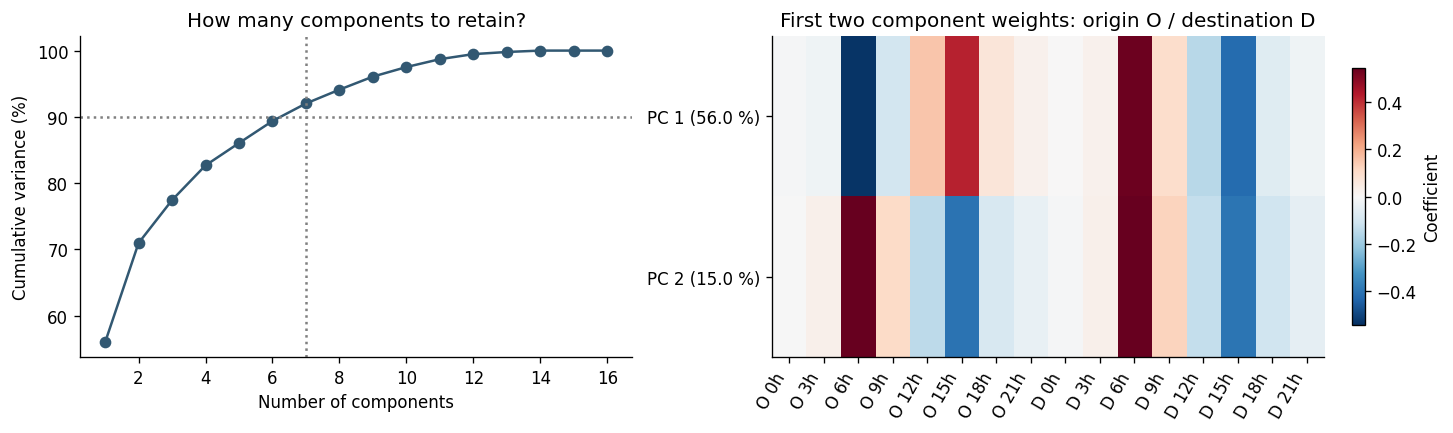

In [9]:
fig,axes=plt.subplots(1,2,figsize=(12,3.5),layout='constrained')
axes[0].plot(np.arange(1,17),100*flow_pca.explained_variance_ratio_.cumsum(),'o-',color='#325872')
axes[0].axhline(90,color='grey',ls=':')
axes[0].axvline(flow_n_axes,color='grey',ls=':')
axes[0].set(xlabel='Number of components',ylabel='Cumulative variance (%)',title='How many components to retain?')
loadings=flow_pca.components_[:2]
bound=np.abs(loadings).max()
im=axes[1].imshow(loadings,aspect='auto',cmap='RdBu_r',vmin=-bound,vmax=bound)
axes[1].set_xticks(range(16),[f'O {3*i}h'for i in range(8)]+[f'D {3*i}h'for i in range(8)],rotation=60,ha='right')
axes[1].set_yticks([0,1],[f'PC {i+1} ({100*flow_pca.explained_variance_ratio_[i]:.1f} %)'for i in range(2)])
axes[1].set_title('First two component weights: origin O / destination D')
fig.colorbar(im,ax=axes[1],label='Coefficient',shrink=.8)
plt.show()

**Reading the PCA:** seven components preserve 92% of variance. The first (about 56%) contrasts endpoint exchange directions across morning and later hours; the second (about 15%) reflects more common variation at both endpoints. Heatmap colours are signed component weights, not journey classes; axis signs are arbitrary.

K=3 has the highest validation silhouette among K=2–6. Names are assigned after inspecting the learned signatures: toward morning-receiving poles, less polarized links, and reverse direction.

## 5. Describe usage in the final period

The table uses all final-period trips with documented endpoint context. Morning means 06:00–10:00; evening means 16:00–20:00. Electric share is calculated among trips with known propulsion; the curves below use weekdays only, so their denominator differs from the all-day table.

,Share_pct,Duration_min,Morning_pct,Evening_pct,Weekend_pct,Electric_pct
context_profile,,,,,,
Toward morning-receiving poles,13.9,10.0,43.8,16.1,15.8,9.9
Less polarized links,72.1,12.0,12.9,29.6,26.3,16.4
Reverse direction,14.0,10.0,8.4,37.6,14.9,8.4


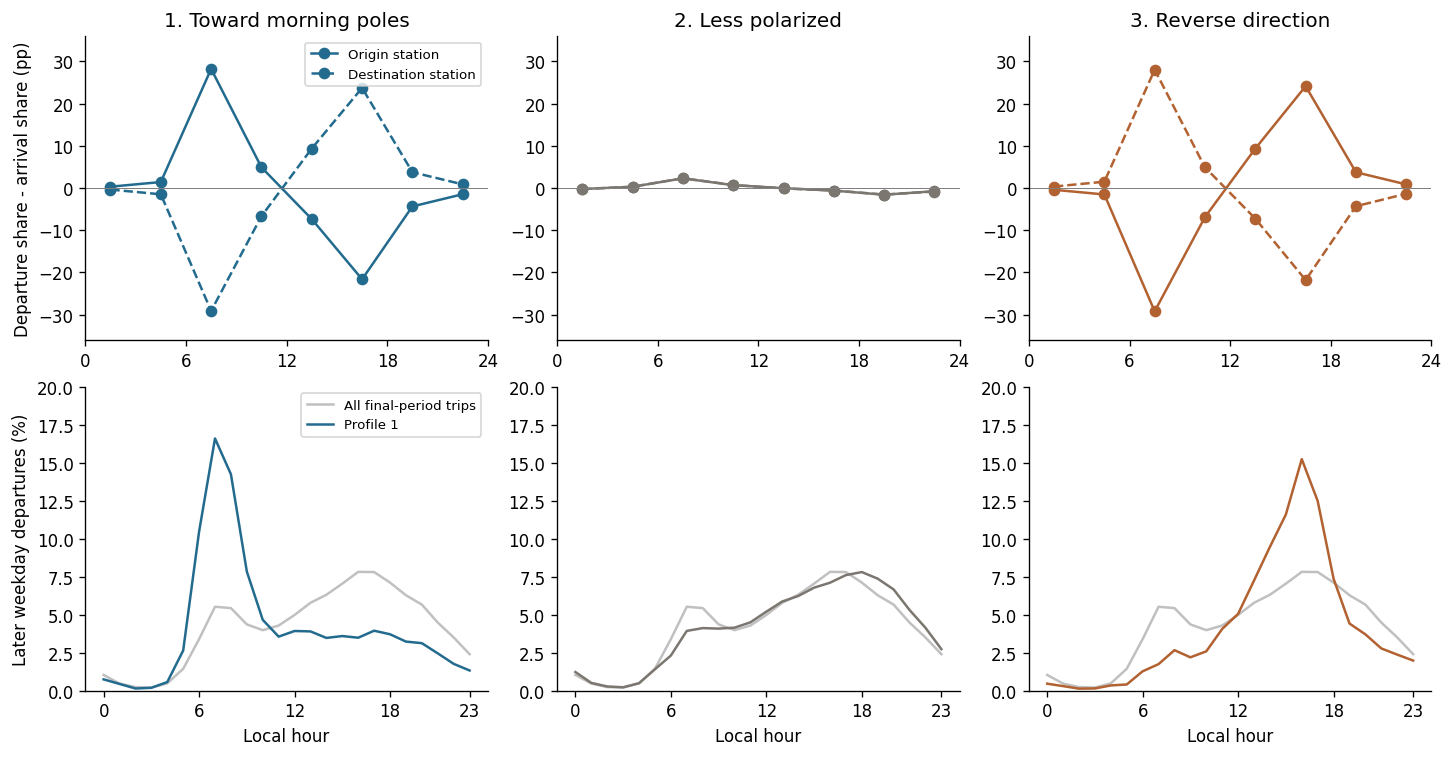

In [10]:
flow_names = {1:'Toward morning-receiving poles',
              2:'Less polarized links',3:'Reverse direction'}
assert flow_k == 3, 'Review profile interpretation if K changes.'
final_trips = flow_trips.loc[flow_trips.period.eq('test')].copy()
final_trips['morning'] = final_trips.local_start_hour.between(6,10,inclusive='left')
final_trips['evening'] = final_trips.local_start_hour.between(16,20,inclusive='left')
final_trips['prolonged'] = final_trips.physical_profile.eq(2)
flow_profiles = final_trips.groupby('context_profile').agg(
    Count=('trip_row','size'), Duration_min=('duration_min','median'),
    Morning_pct=('morning',lambda s:100*s.mean()), Evening_pct=('evening',lambda s:100*s.mean()),
    Weekend_pct=('weekend',lambda s:100*s.mean()),
    Electric_pct=('propulsion_type', lambda s:100*s.dropna().eq('electric_assist').mean()),
    Long_duration_pct=('prolonged',lambda s:100*s.mean()))
flow_profiles.insert(1,'Share_pct',100*flow_profiles.Count/len(final_trips))
display(flow_profiles[['Share_pct','Duration_min','Morning_pct','Evening_pct','Weekend_pct','Electric_pct']].rename(index=flow_names).round(1))


colors=['#236b8e','#7b766f','#b26131']
signature_means=flow_trips.groupby('context_profile')[flow_columns].mean()
weekday_final=final_trips.loc[final_trips.weekend.eq(0)]
hourly=pd.crosstab(weekday_final.context_profile,np.floor(weekday_final.local_start_hour).astype(int)).reindex(columns=range(24),fill_value=0)
hourly=100*hourly.div(hourly.sum(axis=1),axis=0)
global_hour=np.bincount(np.floor(weekday_final.local_start_hour).astype(int),minlength=24)
global_hour=100*global_hour/global_hour.sum()
fig,axes=plt.subplots(2,3,figsize=(12,6.2),layout='constrained')
for i,k in enumerate([1,2,3]):
    means=signature_means.loc[k]
    axes[0,i].plot(np.arange(8)*3+1.5,100*means.iloc[:8],'-o',color=colors[i],label='Origin station')
    axes[0,i].plot(np.arange(8)*3+1.5,100*means.iloc[8:],'--o',color=colors[i],label='Destination station')
    axes[0,i].axhline(0,color='grey',lw=.6)
    axes[0,i].set(title=f'{k}. '+['Toward morning poles','Less polarized','Reverse direction'][i],xticks=[0,6,12,18,24],ylim=(-36,36))
    axes[1,i].plot(range(24),global_hour,color='silver',label='All final-period trips')
    axes[1,i].plot(range(24),hourly.loc[k],color=colors[i],label=f'Profile {k}')
    axes[1,i].set(xlabel='Local hour',xticks=[0,6,12,18,23],ylim=(0,max(20,hourly.to_numpy().max()*1.1)))
axes[0,0].set_ylabel('Departure share - arrival share (pp)')
axes[1,0].set_ylabel('Later weekday departures (%)')
axes[0,0].legend(fontsize=8)
axes[1,0].legend(fontsize=8)
plt.show()

**Observation:** the three contexts account for about 14%, 72% and 14% of documented final-period trips. Morning departures represent 43.8%, 12.9% and 8.4%, respectively, even though the departure hour of the individual trip is not an active feature.

**Interpretation and limit:** these are contrasting link-use rhythms. They do not establish commuting, personal preferences or return trips by the same rider; the broad less-polarized group remains heterogeneous. Propulsion differences may reflect the local fleet rather than individual choice.

## 6. Spatial description of the existing journey profiles

Use the supplied system centre; it is not an estimated destination or a city-wide activity centre. For each journey compute **(end-to-centre distance − start-to-centre distance) / system scale**: negative means inward and positive means outward. The scale is the 90th percentile of both endpoint radii in the learning period, so orientation is relative to the observed extent of that system.

Require 100 learning trips and a positive scale. Flag centres outside the learning endpoint 1st–99th percentile bounding box expanded by 25% on each side; exclude these unsupported cases only from this spatial description. This is a transparent plausibility screen, not proof that the remaining centres are correct. Compare distributions on the final period and perturb centres by 5% of the scale to assess sensitivity.

Boxes span the 25th–75th percentiles, their line is the median and whiskers mark the 10th–90th percentiles; tails are hidden only in the plot. The physical panel covers all spatially eligible final-period journeys, while the context panel uses the subset with documented signatures.

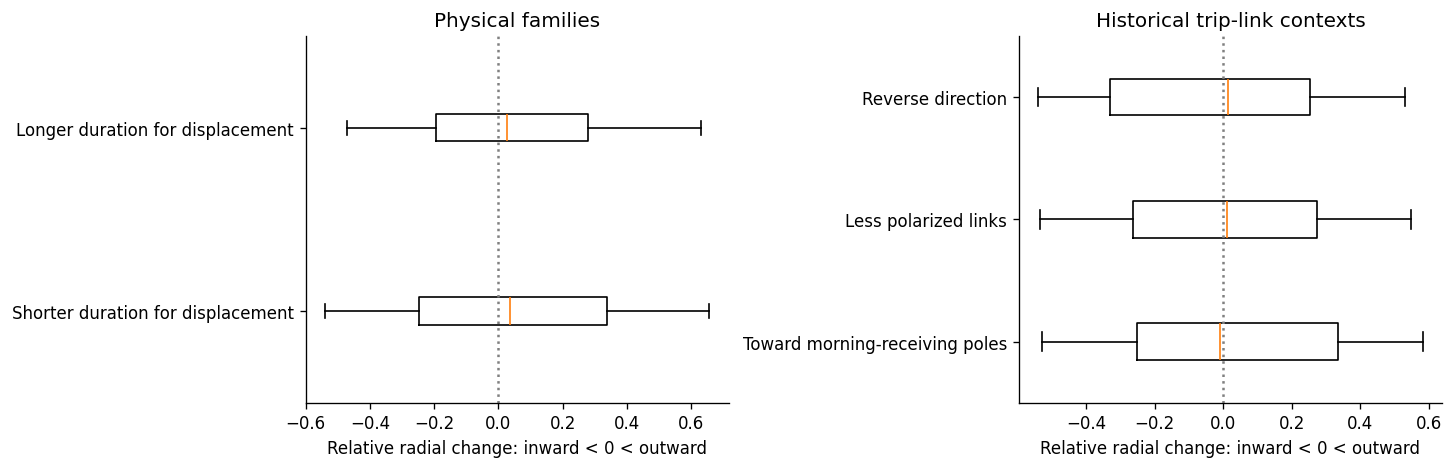

,Representation,Profile,Count,P10,Median,P90
0,physical_profile,Shorter duration for displacement,164182,-0.540,0.037,0.657
1,physical_profile,Longer duration for displacement,49989,-0.473,0.027,0.632
2,context_profile,Toward morning-receiving poles,16360,-0.529,-0.009,0.582
3,context_profile,Less polarized links,88105,-0.534,0.009,0.547
4,context_profile,Reverse direction,16525,-0.540,0.014,0.529


Spatial scope: 214,171 final-period trips in 156 systems; 156/185 systems pass the learning-period screen.
Centre perturbation: minimum directional agreement 96.7%.


In [11]:
spatial_base = trips[['trip_row', 'city_id', 'period', 'physical_profile', 'city_lat', 'city_lon', 'lat_start', 'lon_start', 'lat_end', 'lon_end']].copy()

def centre_distance(frame, side, centre_lat, centre_lon):
    lat = np.deg2rad(frame[f'lat_{side}'])
    origin_lat = np.deg2rad(centre_lat)
    delta_lon = np.deg2rad(frame[f'lon_{side}'] - centre_lon)
    a = np.sin((lat - origin_lat) / 2)**2
    a += np.cos(lat) * np.cos(origin_lat) * np.sin(delta_lon / 2)**2
    return 12742.0176 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

for side in ['start', 'end']:
    spatial_base[f'radius_{side}'] = centre_distance(spatial_base, side, spatial_base.city_lat, spatial_base.city_lon)
learning = spatial_base.loc[spatial_base.period == 'train']
radii = pd.concat([learning[['city_id', 'radius_start']].rename(columns={'radius_start': 'radius'}),
                   learning[['city_id', 'radius_end']].rename(columns={'radius_end': 'radius'})])
system_scale = radii.groupby('city_id').radius.quantile(.9)
centre_ok = learning.groupby('city_id').size().ge(100) & system_scale.gt(0)
for coordinate in ['lat', 'lon']:
    points = pd.concat([learning[['city_id', f'{coordinate}_{side}']].rename(
        columns={f'{coordinate}_{side}': 'value'}) for side in ['start', 'end']])
    bounds = points.groupby('city_id').value.quantile([.01, .99]).unstack()
    padding = .25 * (bounds[.99] - bounds[.01])
    centre = cities.set_index('id')[coordinate].reindex(bounds.index)
    centre_ok &= centre.between(bounds[.01] - padding, bounds[.99] + padding)
spatial_base['radial_relative'] = (spatial_base.radius_end - spatial_base.radius_start) / spatial_base.city_id.map(system_scale)
spatial = spatial_base.loc[spatial_base.period.eq('test') & spatial_base.city_id.map(centre_ok).fillna(False)].copy()
spatial = spatial.dropna(subset=['radial_relative'])
spatial = spatial.join(flow_trips.set_index('trip_row').context_profile, on='trip_row')
print(f'Spatial scope: {len(spatial):,} final-period trips in {spatial.city_id.nunique()} systems; '
      f'{int(centre_ok.sum())}/{len(centre_ok)} systems pass the learning-period screen.')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
spatial_rows = []
for ax, column, names in [(axes[0], 'physical_profile', motion_names),
                          (axes[1], 'context_profile', flow_names)]:
    groups = [spatial.loc[spatial[column] == k, 'radial_relative'].to_numpy() for k in names]
    ax.boxplot(groups, orientation='horizontal', tick_labels=list(names.values()),
               whis=(10, 90), showfliers=False)
    ax.axvline(0, color='grey', linestyle=':')
    ax.set(xlabel='Relative radial change: inward < 0 < outward')
    for k, values in zip(names, groups):
        spatial_rows.append({'Representation': column, 'Profile': names[k], 'Count': len(values),
                             'P10': np.quantile(values, .1), 'Median': np.median(values),
                             'P90': np.quantile(values, .9)})
axes[0].set_title('Physical families')
axes[1].set_title('Historical trip-link contexts')
plt.show()
spatial_summary = pd.DataFrame(spatial_rows)
display(spatial_summary.round(3))

centre_sensitivity = []
scale = spatial.city_id.map(system_scale)
for north, east in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
    shifted_lat = spatial.city_lat + north * .05 * scale / 111.2
    shifted_lon = spatial.city_lon + east * .05 * scale / (111.2 * np.cos(np.deg2rad(spatial.city_lat)))
    shifted = (centre_distance(spatial, 'end', shifted_lat, shifted_lon) -
               centre_distance(spatial, 'start', shifted_lat, shifted_lon)) / scale
    centre_sensitivity.append((np.sign(shifted) == np.sign(spatial.radial_relative)).mean())
print(f'Centre perturbation: minimum directional agreement {100 * min(centre_sensitivity):.1f}%.')

**Observation:** across 214,171 eligible final-period journeys in 156 systems, physical-family median relative radial changes are +0.037 and +0.027; context medians are −0.009, +0.009 and +0.014, with strongly overlapping distributions.

**Interpretation:** this spatial description does not support a clear inward/outward explanation of the existing groups; morning-receiving poles need not be geographic city centres.

**Limit:** centre perturbations preserve at least 96.7% of directional signs under the tested shifts, but centres remain approximate and screened systems are a selected subset; the context panel further requires documented endpoint signatures.

## 7. Cross physical families and historical link contexts

Use the same final-period cohort with both labels. The bars show the share of longer-duration journeys within each context; the reference line uses that same cohort. These combinations are not six newly discovered classes.

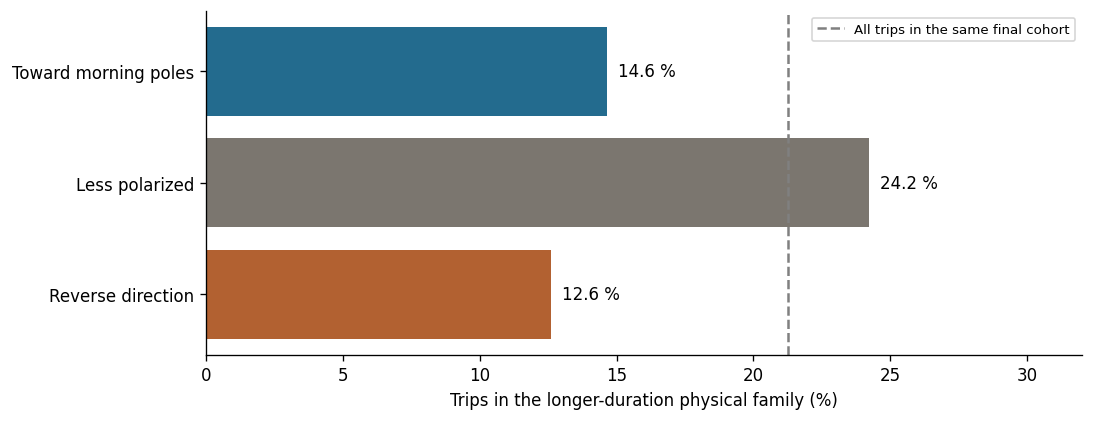

Within-system check: 59 comparable systems, median difference 6.0 pp; positive difference in 83.1% of systems.


In [12]:
cross_counts=pd.crosstab(final_trips.context_profile,final_trips.physical_profile).reindex(index=[1,2,3],columns=[1,2],fill_value=0)
cross_percent=100*cross_counts.div(cross_counts.sum(axis=1),axis=0)
overall_prolonged=100*final_trips.physical_profile.eq(2).mean()
fig,ax=plt.subplots(figsize=(9,3.4),layout='constrained')
ax.barh(['Toward morning poles','Less polarized','Reverse direction'],cross_percent[2],color=colors)
ax.axvline(overall_prolonged,color='grey',ls='--',label='All trips in the same final cohort')
for i,value in enumerate(cross_percent[2]):ax.text(value+.4,i,f'{value:.1f} %',va='center')
ax.set(xlabel='Trips in the longer-duration physical family (%)',xlim=(0,32))
ax.invert_yaxis()
ax.legend(fontsize=8)
plt.show()

cross_control=final_trips.assign(mixed=final_trips.context_profile.eq(2),long=final_trips.physical_profile.eq(2))
within_city=cross_control.groupby(['city_id','mixed']).agg(n=('trip_row','size'),long=('long','mean')).unstack('mixed')
eligible=within_city['n'][True].ge(30)&within_city['n'][False].ge(30)
within_city_delta=100*(within_city.loc[eligible,('long',True)]-within_city.loc[eligible,('long',False)])
print(f'Within-system check: {len(within_city_delta)} comparable systems, '
      f'median difference {within_city_delta.median():.1f} pp; '
      f'positive difference in {100*within_city_delta.gt(0).mean():.1f}% of systems.')

**Observation:** longer-duration journeys represent about 24% of less-polarized links, compared with 13–15% in the directional contexts. Within 59 sufficiently represented systems, the median difference is +6 percentage points and is positive in 83%.

**Interpretation and limit:** the association also appears within systems, but is smaller locally and not universal. It does not identify a journey purpose or establish a causal explanation.

## 8. Validation and reproducibility

The following checks refit the complete physical or PCA–K-means pipelines: resampling, held-out systems, physical extremes and duration rounding, and functional components/smoothing. Later signatures test changing historical context with the model fixed; same-link/propulsion duration references and within-system morning contrasts check interpretation.

ARI measures agreement between partitions, not behavioural truth. Silhouettes from different representations cannot be ranked directly. Fixed seeds and printed package versions support reproducibility; versions, row order or input changes may still alter results. All checks below, including GPS, margins, concentration and bootstrap diagnostics, are recalculated; the historical experiments in the last table are not.

In [13]:
physical_checks = []
def refit_motion(train_indices, evaluation_indices, values=log_motion, seed=42):
    scaler = StandardScaler().fit(values[train_indices])
    with threadpool_limits(limits=2):
        model = GaussianMixture(n_components=physical_k,n_init=4,max_iter=300,
            reg_covar=1e-4,random_state=seed).fit(scaler.transform(values[train_indices]))
    return model.predict(scaler.transform(values[evaluation_indices]))
for seed in [11,73]:
    sample = np.random.default_rng(seed).choice(period_ids['train'],80000,replace=False)
    pred = refit_motion(sample,physical_test,seed=seed)
    physical_checks.append((f'Resample ({seed})',adjusted_rand_score(motion_raw[physical_test],pred)))
limits = trips.iloc[period_ids['train']][['duration_min','displacement_rate_kmh']].quantile(.99)
not_extreme = (trips.duration_min.le(limits.duration_min)&trips.displacement_rate_kmh.le(limits.displacement_rate_kmh)).to_numpy()
sample = np.random.default_rng(42).choice(period_ids['train'][not_extreme[period_ids['train']]],80000,replace=False)
pred = refit_motion(sample,physical_test)
physical_checks.append(('Without training extremes',adjusted_rand_score(motion_raw[physical_test],pred)))
jittered = log_motion.copy()
jittered[:,0] = np.log(trips.duration_min.to_numpy()+np.random.default_rng(42).uniform(-.5,.5,len(trips)))
pred = refit_motion(physical_train,physical_test,values=jittered)
physical_checks.append(('Duration jitter +/-30 seconds',adjusted_rand_score(motion_raw[physical_test],pred)))
del jittered
a,b = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=2026).split(
    period_ids['train'],groups=trips.iloc[period_ids['train']].city_id))
sample = np.random.default_rng(42).choice(period_ids['train'][a],80000,replace=False)
heldout_cities = set(trips.iloc[period_ids['train'][b]].city_id)
evaluation = physical_test[trips.iloc[physical_test].city_id.isin(heldout_cities)]
pred = refit_motion(sample,evaluation)
physical_checks.append(('Systems excluded from training',adjusted_rand_score(motion_raw[evaluation],pred)))
physical_checks = pd.DataFrame(physical_checks,columns=['Check','ARI']).set_index('Check')

In [14]:
route_keys = ['city_id','station_id_start','station_id_end','propulsion_context']
route_reference = trips.loc[trips.period.eq('train')].dropna(subset=route_keys).groupby(route_keys).duration_min.agg(['median','size'])
route_reference = route_reference.loc[route_reference['size'].ge(20)]
route_check = trips.loc[trips.period.eq('test')].join(route_reference,on=route_keys,validate='many_to_one').dropna(subset=['median'])
route_check['relative_duration'] = route_check.duration_min/route_check['median']
route_ratios = route_check.groupby('physical_profile').relative_duration.median()

In [15]:
flow_checks = []
def refit_flow(values,train_indices,evaluation_indices,seed=42,n_axes=None):
    pca = PCA(svd_solver='full').fit(values[train_indices])
    n = int(np.searchsorted(pca.explained_variance_ratio_.cumsum(),.9)+1) if n_axes is None else n_axes
    with threadpool_limits(limits=2):
        model = KMeans(n_clusters=flow_k,n_init=10,random_state=seed).fit(pca.transform(values[train_indices])[:,:n])
    return model.predict(pca.transform(values[evaluation_indices])[:,:n])
for seed in [11,73]:
    sample = np.random.default_rng(seed).choice(flow_pools['train'],80000,replace=False)
    pred = refit_flow(flow_X,sample,flow_test,seed)
    flow_checks.append((f'Resample ({seed})',adjusted_rand_score(flow_raw[flow_test],pred)))
a,b = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=2026).split(
    flow_pools['train'],groups=flow_trips.iloc[flow_pools['train']].city_id))
sample = np.random.default_rng(42).choice(flow_pools['train'][a],80000,replace=False)
heldout_flow_cities = set(flow_trips.iloc[flow_pools['train'][b]].city_id)
evaluation = flow_test[flow_trips.iloc[flow_test].city_id.isin(heldout_flow_cities)]
pred = refit_flow(flow_X,sample,evaluation)
flow_checks.append(('Systems excluded from centre fitting',adjusted_rand_score(flow_raw[evaluation],pred)))
for axes in [2,5,14]:
    pred = refit_flow(flow_X,flow_train,flow_test,n_axes=axes)
    flow_checks.append((f'{axes} components instead of {flow_n_axes}',adjusted_rand_score(flow_raw[flow_test],pred)))
for alpha in [1,6]:
    alternative,_ = station_signatures(events.loc[events.old],alpha=alpha)
    attached,_ = attach_signatures(flow_trips[trips.columns],alternative)
    assert attached.trip_row.tolist() == flow_trips.trip_row.tolist()
    values = attached[flow_columns].to_numpy()
    pred = refit_flow(values,flow_train,flow_test)
    flow_checks.append((f'Smoothing {alpha} instead of 3',adjusted_rand_score(flow_raw[flow_test],pred)))
flow_checks = pd.DataFrame(flow_checks,columns=['Check','ARI']).set_index('Check')

In [16]:
future_signatures,_ = station_signatures(events.loc[~events.old],min_events=60)
future_attached,_ = attach_signatures(flow_trips[trips.columns],future_signatures)
common_indices = flow_trips.index[flow_trips.trip_row.isin(future_attached.trip_row)].to_numpy()
assert np.array_equal(flow_trips.loc[common_indices,'trip_row'],future_attached.trip_row)
future_Z = flow_pca.transform(future_attached[flow_columns].to_numpy())[:,:flow_n_axes]
future_labels = flow_model.predict(future_Z)
context_ari = adjusted_rand_score(flow_raw[common_indices],future_labels)
context_agreement = np.mean(flow_raw[common_indices]==future_labels)
margin_checks = []
for threshold in [.15,.25,.35]:
    keep = flow_trips.loc[common_indices,'margin'].ge(threshold).to_numpy()
    margin_checks.append({'Minimum margin':threshold,'Common coverage (%)':100*keep.mean(),
        'Same later profile (%)':100*np.mean(flow_raw[common_indices][keep]==future_labels[keep])})
margin_checks = pd.DataFrame(margin_checks)

by_city = final_trips.loc[final_trips.weekend.eq(0)].groupby(['city_id','context_profile']).agg(n=('trip_row','size'),morning=('morning','mean')).unstack()
supported = by_city['n'][1].ge(30)&by_city['n'][3].ge(30)
city_effect = 100*(by_city.loc[supported,('morning',1)]-by_city.loc[supported,('morning',3)])
bootstrap = np.random.default_rng(2026).choice(city_effect.to_numpy(),size=(2000,len(city_effect)),replace=True)
city_interval = np.quantile(np.median(bootstrap,axis=1),[.025,.975])
city_max = flow_trips.groupby('context_profile').city_id.apply(lambda s:s.value_counts(normalize=True).max())
route_max = flow_trips.groupby('context_profile').apply(
    lambda g:g.groupby(['city_id','station_id_start','station_id_end']).size().max()/len(g),include_groups=False)

def station_offset(frame,side):
    p1,p2 = np.deg2rad(frame[f'lat_{side}']),np.deg2rad(frame[f'station_{side}_lat'])
    dl = np.deg2rad(frame[f'lon_{side}']-frame[f'station_{side}_lon'])
    a = np.sin((p1-p2)/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 12742.0176*np.arcsin(np.sqrt(np.clip(a,0,1)))
gps_supported = station_offset(final_trips,'start').le(.25)&station_offset(final_trips,'end').le(.25)
gps_effect = final_trips.loc[gps_supported&final_trips.weekend.eq(0)].groupby('context_profile').morning.mean()*100

In [17]:
evaluation_summary=pd.DataFrame([
    {'Representation':'Physical','Check':'Resamples, extremes, rounding, held-out systems',
     'Minimum ARI':physical_checks.ARI.min()},
    {'Representation':'Functional','Check':'Resamples, held-out systems, components, smoothing',
     'Minimum ARI':flow_checks.ARI.min()},
    {'Representation':'Functional','Check':'Context re-estimated in a later period',
     'Minimum ARI':context_ari}])
display(evaluation_summary.round(3).set_index('Representation'))
print(f'Re-estimated context: {100*context_agreement:.1f}% identical labels across {len(common_indices):,} trips ; '
      'updated contexts are less stable than resampled model centres.')
print(f'Median morning-share contrast between directions: {city_effect.median():.1f} pp across '
      f'{len(city_effect)} sufficiently represented systems; same sign in {100*city_effect.gt(0).mean():.1f}% of systems.')
print(f'Same directed link and propulsion: median relative durations {route_ratios.loc[1]:.2f} and {route_ratios.loc[2]:.2f}, '
      f'over {len(route_check):,} trips with historical references.')

,Check,Minimum ARI
Representation,,
Physical,"Resamples, extremes, rounding, held-out systems",0.971
Functional,"Resamples, held-out systems, components, smoot...",0.941
Functional,Context re-estimated in a later period,0.636


Re-estimated context: 88.9% identical labels across 664,328 trips ; updated contexts are less stable than resampled model centres.
Median morning-share contrast between directions: 36.7 pp across 63 sufficiently represented systems; same sign in 98.4% of systems.
Same directed link and propulsion: median relative durations 0.94 and 2.37, over 125,940 trips with historical references.


**Observation:** minimum ARI is 0.971 for the physical checks and 0.941 for functional refits; updating historical signatures gives ARI 0.636 and 88.9% unchanged labels. At the same directed link and propulsion, median duration/reference is 0.94 versus 2.37 for the physical families.

**Interpretation and limit:** physical families are robust under the tested perturbations; link contexts evolve more over time. These are stable descriptive partitions with gradual boundaries, not proof of separate traveller populations. Endpoint coverage, system composition, approximate centres and unknown upstream selection limit generalization.

In [18]:
assert len(trips)==physical_profiles.Count.sum()
assert len(final_trips)==flow_profiles.Count.sum()==cross_counts.to_numpy().sum()
assert np.allclose(cross_percent.sum(axis=1),100)
assert np.isfinite(motion_X).all() and np.isfinite(flow_X).all()
assert set(flow_pools['train']).isdisjoint(flow_pools['test'])
assert set(flow_pools['validation']).isdisjoint(flow_pools['test'])
assert trips.trip_row.is_unique and flow_trips.trip_row.is_unique
assert len(trips)==n_trips
print('Checks passed: joins, counts, scopes, matrices and periods are consistent.')

Checks passed: joins, counts, scopes, matrices and periods are consistent.


## 9. What we tried and why it was retained or set aside

A, E and F are reproduced here; H is reproduced as a comparable-link control. B, C, D, G, I and J are historical exploration summaries, not additional experiments rerun by this notebook.

| Trial | Hypothesis | Finding and decision |
|---|---|---|
| A — Preparation | Consistent units, joins and local time make comparisons meaningful. | Retained as common preparation. |
| B — Timing | Duration/rate and calendar features reveal journey profiles. | Four readable regions, but a timing continuum and sensitivity to extremes; secondary. |
| C — Initial spatial | Relative centrality and weekend distinguish journeys. | Inward/outward descriptions useful; weekend group partly induced by input and centres approximate. |
| D — Global combination | Combining timing and space gives richer groups. | Mainly timing groups; no convincing additional spatial separation. |
| E — Physical | Duration versus displacement reveals journey forms. | Two robust GMM families, with uncertain membership; retained. |
| F — Historical context | Endpoint exchange signatures reveal link-use patterns. | Three contexts and contrasting later hours; retained, with 60% coverage. |
| G — Enriched geometry | Radial change misses travel between sectors. | Transverse journeys described; detailed groups sensitive to centre choice, not retained as another main model. |
| H — Relative duration | Compare trips to the same link and propulsion history. | Largely confirms physical families; retained as a control, not a new taxonomy. |
| I — Link timing signatures | Hour × weekday/weekend can split less-polarized links. | Best silhouette about 0.133; no convincing extra subprofiles. |
| J — HDBSCAN | Density clustering reveals clearer groups. | Mostly weekday/weekend in the tested representation; no new usage insight retained. |

The descriptive spatial comparison borrows the radial-change idea explored in the team’s work, with within-system scaling and centre checks.

## Conclusion

Duration–displacement distinguishes two physical journey families; historical endpoint exchanges distinguish three link-use contexts. Their cross-tabulation shows more longer-duration journeys on less-polarized links; spatial distributions provide a separate descriptive check.

We can describe how journeys differ, but cannot observe commuting, leisure, sport, stops, family travel or personal identity. Future work should validate the representations on genuinely new data and investigate heterogeneous links, rather than multiply clustering algorithms.

Method references: [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [clustering evaluation](https://scikit-learn.org/stable/modules/clustering.html), [Gaussian mixtures](https://scikit-learn.org/stable/modules/mixture.html), [components, clusters and entropy](https://pmc.ncbi.nlm.nih.gov/articles/PMC2953822/). Numerical findings come from the supplied data.